In [1]:
import sys
sys.path.append('../scripts')
from utils.cftp_func import *
import glob

In [114]:
graph_type = 'ER'
coup_type = 'ising'
d = 4
if graph_type == 'ER' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/d))
    beta_uni = np.arctanh(1/d)
    print(f"beta_uni = {beta_uni:.6f}, beta_SG = {beta_SG:.6f}")
elif graph_type == 'ER' and coup_type == 'gauss':
    beta_uni = solve_beta_critical_gauss(d=4)
    print(f"beta_uni = {beta_uni:.6f}")

beta_uni = 0.255413, beta_SG = 0.549306


In [115]:
dfs = [pd.read_csv(f) for f in glob.glob(f'../results/tmp/coal_time_{graph_type}_{coup_type}_d{d}_beta*.csv')]
df = pd.concat(dfs, ignore_index=True)
df

,beta,sampler,lazy,init_mode,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
0,0.26,F_beta_Glauber,False,full_star,50,100000000,100,50,2.731708e+04,1.266241e+05
1,0.26,F_beta_Glauber,False,full_star,50,100000000,1000,49,3.055199e+06,9.722481e+06
2,0.26,F_beta_Glauber,False,full_star,50,100000000,10000,5,3.318818e+07,3.165651e+07
3,0.26,F_beta_Glauber,False,full_star,50,100000000,100000,0,NaN,NaN
4,0.25,F_beta_Glauber,False,full_star,50,100000000,100,50,7.531780e+03,1.076116e+04
5,0.25,F_beta_Glauber,False,full_star,50,100000000,1000,50,1.738876e+05,1.348495e+05
6,0.25,F_beta_Glauber,False,full_star,50,100000000,10000,50,3.287373e+06,1.078401e+06
7,0.25,F_beta_Glauber,False,full_star,50,100000000,100000,50,5.310141e+07,1.007281e+07
8,0.25,F_beta_Glauber,False,full_star,50,1000000000,100,50,7.676700e+03,8.459154e+03
9,0.25,F_beta_Glauber,False,full_star,50,1000000000,1000,50,2.566940e+05,4.073928e+05


# Proba of coalescence

In [116]:
max_iter_plot = 10**9
N_plot = [10**2,10**3,10**4,10**5]
mask = (
    (df['N'].isin(N_plot)) &
    (df['max_iter'] == max_iter_plot) 
)
df_filtered = df[mask]
df_filtered

,beta,sampler,lazy,init_mode,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
8,0.25,F_beta_Glauber,False,full_star,50,1000000000,100,50,7.676700e+03,8.459154e+03
9,0.25,F_beta_Glauber,False,full_star,50,1000000000,1000,50,2.566940e+05,4.073928e+05
10,0.25,F_beta_Glauber,False,full_star,50,1000000000,10000,50,3.519148e+06,1.378954e+06
11,0.25,F_beta_Glauber,False,full_star,50,1000000000,100000,50,5.416591e+07,1.340813e+07
16,0.24,F_beta_Glauber,False,full_star,50,1000000000,100,50,5.419920e+03,6.515463e+03
17,0.24,F_beta_Glauber,False,full_star,50,1000000000,1000,50,9.484598e+04,4.511395e+04
18,0.24,F_beta_Glauber,False,full_star,50,1000000000,10000,50,1.620993e+06,4.390832e+05
19,0.24,F_beta_Glauber,False,full_star,50,1000000000,100000,50,2.371678e+07,4.254305e+06
24,0.27,F_beta_Glauber,False,full_star,50,1000000000,100,50,3.046060e+04,9.172038e+04
25,0.27,F_beta_Glauber,False,full_star,50,1000000000,1000,42,1.223623e+08,2.080914e+08


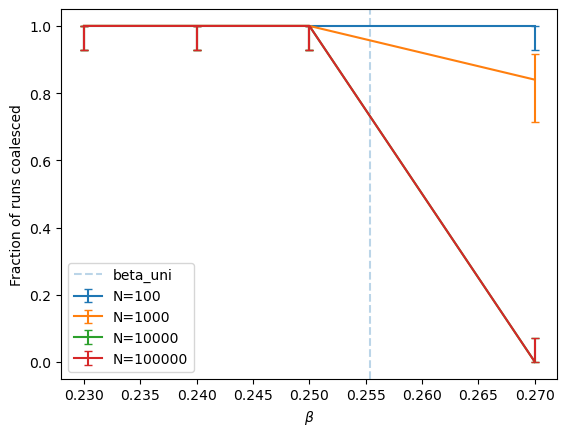

In [117]:
for N in df_filtered['N'].unique():
    sub_df = df_filtered[df_filtered['N'] == N].sort_values('beta')
    k = sub_df['n_coal'].values
    n = sub_df['n_runs'].values
    p, err_down, err_up = wilson_interval(k, n)
    plt.errorbar(sub_df['beta'], p,
                 yerr=[err_down, err_up],
                 label=f'N={N}', capsize=3)

plt.axvline(beta_uni, linestyle='--', alpha=0.3, label='beta_uni')
plt.xlabel(r'$\beta$')
plt.ylabel('Fraction of runs coalesced')
plt.legend()
plt.show()

# Scaling of coalescence times

In [118]:
max_iter_plot = 10**9
if graph_type == 'ER' and coup_type == 'gauss':
    beta_plot = [0.3]#,0.31,0.32,0.2,0.27,0.28,0.29] # beta selection for plotting
elif graph_type == 'ER' and coup_type == 'ising':
    beta_plot = [0.23,0.24,0.25] # beta selection for plotting
else:
    beta_plot = df['beta'].unique()
mask = (
    (df['n_coal'] == df['n_runs']) & # plot only beta values for which every run has coalesced (for unbiased averages)
    (df['beta'].isin(beta_plot)) &
    (df['max_iter'] == max_iter_plot) 
)
df_filtered = df[mask]
df_filtered

,beta,sampler,lazy,init_mode,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
8,0.25,F_beta_Glauber,False,full_star,50,1000000000,100,50,7676.70,8.459154e+03
9,0.25,F_beta_Glauber,False,full_star,50,1000000000,1000,50,256694.02,4.073928e+05
10,0.25,F_beta_Glauber,False,full_star,50,1000000000,10000,50,3519147.60,1.378954e+06
11,0.25,F_beta_Glauber,False,full_star,50,1000000000,100000,50,54165905.14,1.340813e+07
16,0.24,F_beta_Glauber,False,full_star,50,1000000000,100,50,5419.92,6.515463e+03
17,0.24,F_beta_Glauber,False,full_star,50,1000000000,1000,50,94845.98,4.511395e+04
18,0.24,F_beta_Glauber,False,full_star,50,1000000000,10000,50,1620993.40,4.390832e+05
19,0.24,F_beta_Glauber,False,full_star,50,1000000000,100000,50,23716782.58,4.254305e+06
32,0.23,F_beta_Glauber,False,full_star,50,1000000000,100,50,3386.14,2.336540e+03
33,0.23,F_beta_Glauber,False,full_star,50,1000000000,1000,50,62524.44,1.977430e+04


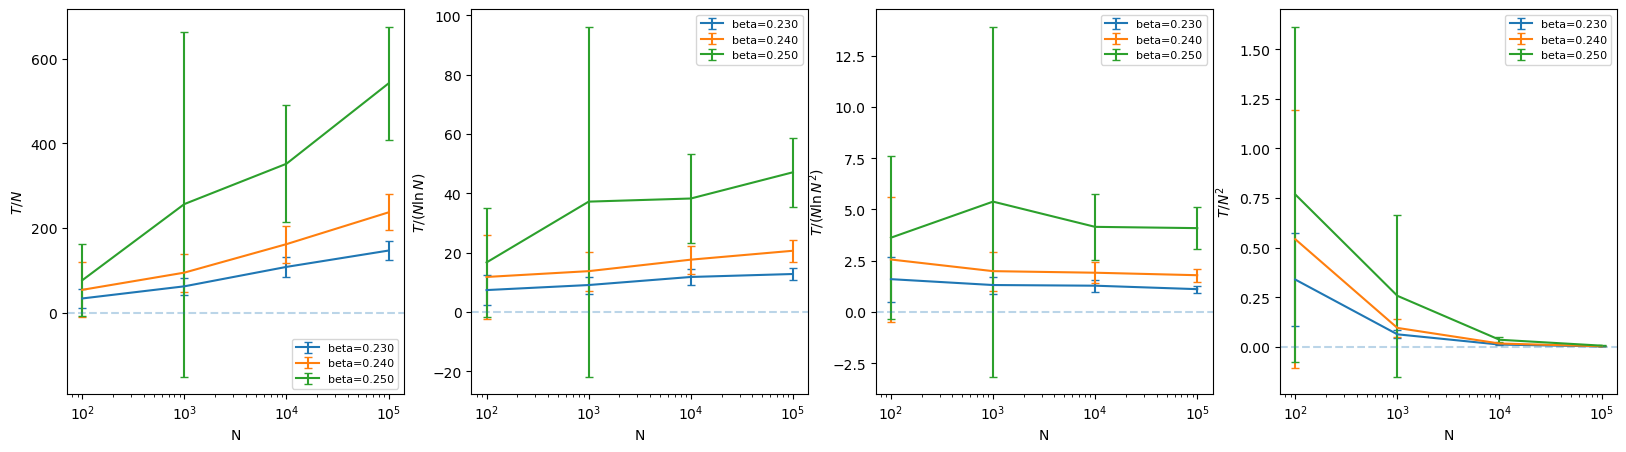

In [119]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
scalings = {
    r'$T / N$': (lambda N, T: T / N, 
                lambda N, T, sT: sT / N),
    r'$T / (N \ln N)$': (lambda N, T: T / (N * np.log(N)), 
                          lambda N, T, sT: sT / (N * np.log(N))),
    r'$T / (N \ln N^2)$': (lambda N, T: T / (N * np.log(N)**2), 
                          lambda N, T, sT: sT / (N * np.log(N)**2)),
    r'$T / N^2$': (lambda N, T: T / N**2, 
                   lambda N, T, sT: sT / N**2),
}
for ax, (label, (scaling_fn, err_fn)) in zip(axes, scalings.items()):
    for beta in sorted(df_filtered['beta'].unique()):
        sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
        N = sub_df['N'].values
        T = sub_df['mean_coal_time'].values
        sT = sub_df['std_coal_time'].values
        ax.errorbar(N, scaling_fn(N, T), yerr=err_fn(N, T, sT), label=f'beta={beta:.3f}', capsize=3)
    ax.axhline(0, linestyle='--', alpha=0.3)
    ax.set_xlabel('N')
    ax.set_ylabel(label)
    ax.set_xscale('log')   
    ax.legend(fontsize=8)
plt.show()

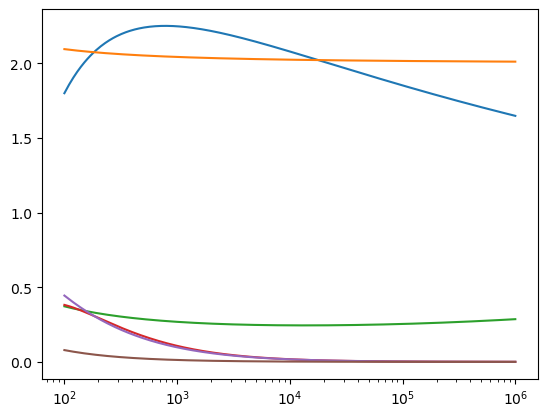

In [120]:
K=30
Q=-100
delta = 1.21
aa = 3
def f(n,K,Q): 
    return K*n*np.log(n)+Q*n
def f2(n,K,Q): 
    return K*n*np.log(n)**2+Q*n
def g(n,aa, delta): 
    return aa*(n**delta)
nr = np.arange(100,10**6,10)
#plt.plot(nr,f(nr,K,Q)/(nr*np.log(nr)) )
#plt.plot(nr,f2(nr,2,2)/(nr*np.log(nr)) )
#plt.plot(nr,g(nr,aa,delta)/(nr*np.log(nr)) )

plt.plot(nr,f(nr,K,Q)/(nr*(np.log(nr)**2)) )
plt.plot(nr,f2(nr,2,2)/(nr*(np.log(nr)**2)) )
plt.plot(nr,g(nr,aa,delta)/(nr*(np.log(nr)**2)) )

plt.plot(nr,f(nr,K,Q)/(nr**2))
plt.plot(nr,f2(nr,2,2)/(nr**2))
plt.plot(nr,g(nr,aa,delta)/(nr**2))

plt.xscale('log')

0.23 [3.45988801 0.84132361]
0.24 [5.82238903 1.24960419]
0.25 [-3.18915201  4.75293159]


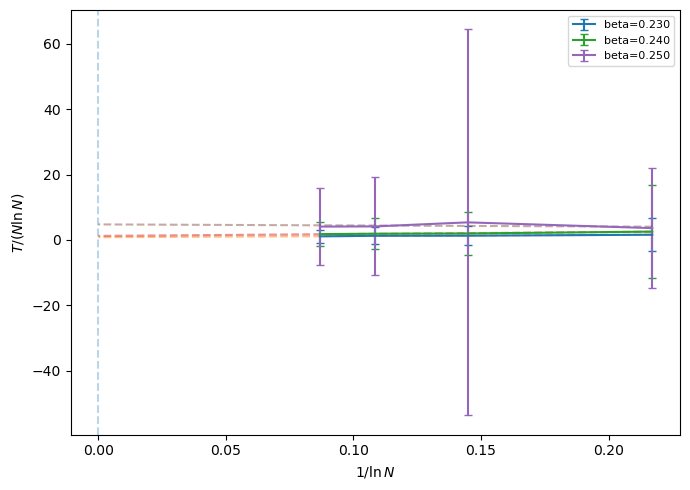

In [121]:
fig, ax = plt.subplots(figsize=(7, 5))

for beta in sorted(df_filtered['beta'].unique()):
    sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
    N = sub_df['N'].values
    T = sub_df['mean_coal_time'].values
    sT = sub_df['std_coal_time'].values
    x = 1 / np.log(N)
    y = T / (N * (np.log(N))**2)
    yerr = sT / (N * np.log(N))
    ax.errorbar(x, y, yerr=yerr, label=f'beta={beta:.3f}', capsize=3)
    coeffs = np.polyfit(x, y, 1)
    print(beta, coeffs)
    x_fit = np.linspace(x.max(), 0, 100)
    ax.plot(x_fit, np.polyval(coeffs, x_fit), linestyle='--', alpha=0.5)

ax.axvline(0, linestyle='--', alpha=0.3)
ax.set_xlabel(r'$1 / \ln N$')
ax.set_ylabel(r'$T / (N \ln N)$')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

0.23 [-41.97737519  16.08385597]
0.24 [-64.60777547  24.92705257]
0.25 [-219.28318941   65.32571824]


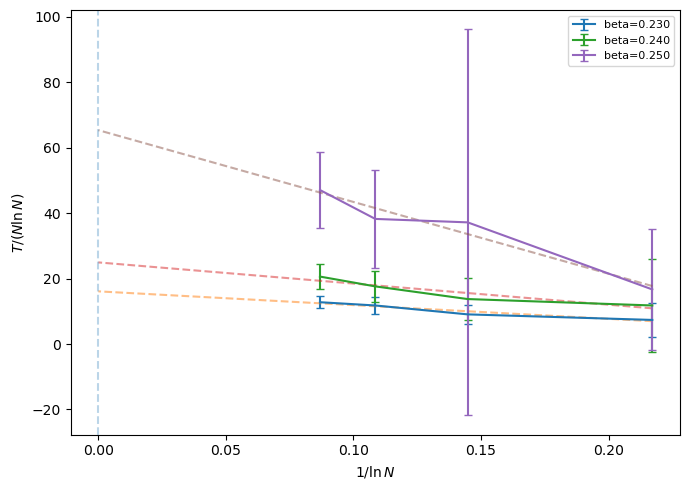

In [122]:
fig, ax = plt.subplots(figsize=(7, 5))

for beta in sorted(df_filtered['beta'].unique()):
    sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
    N = sub_df['N'].values
    T = sub_df['mean_coal_time'].values
    sT = sub_df['std_coal_time'].values
    x = 1 / np.log(N)
    y = T / (N * np.log(N))
    yerr = sT / (N * np.log(N))
    ax.errorbar(x, y, yerr=yerr, label=f'beta={beta:.3f}', capsize=3)
    coeffs = np.polyfit(x, y, 1)
    print(beta, coeffs)
    x_fit = np.linspace(x.max(), 0, 100)
    ax.plot(x_fit, np.polyval(coeffs, x_fit), linestyle='--', alpha=0.5)

ax.axvline(0, linestyle='--', alpha=0.3)
ax.set_xlabel(r'$1 / \ln N$')
ax.set_ylabel(r'$T / (N \ln N)$')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

0.23 [1.21516223 2.59947415]
0.24 [1.2155951  3.03798323]
0.25 [1.2682676 3.3496899]


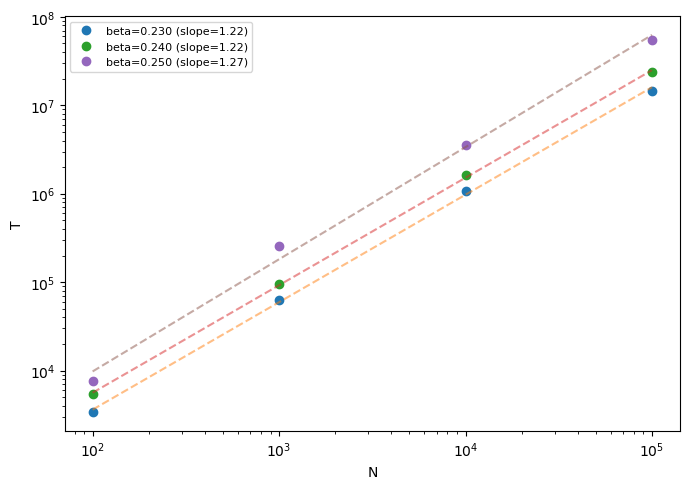

In [123]:
fig, ax = plt.subplots(figsize=(7, 5))

for beta in sorted(df_filtered['beta'].unique()):
    sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
    N = sub_df['N'].values
    T = sub_df['mean_coal_time'].values
    
    # fit log T = alpha * log N + const
    coeffs = np.polyfit(np.log(N), np.log(T), 1)
    print(beta, coeffs)
    alpha = coeffs[0]
    
    ax.loglog(N, T, 'o', label=f'beta={beta:.3f} (slope={alpha:.2f})')
    ax.loglog(N, np.exp(np.polyval(coeffs, np.log(N))), '--', alpha=0.5)

ax.set_xlabel('N')
ax.set_ylabel('T')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()